# Video and Webcam

A video is a sequence of images (frames) shown fast enough to look like motion - so every image operation you know applies frame by frame. This notebook covers reading video files, writing video, frame properties, FPS, and the webcam pattern. To keep it runnable everywhere, we first create a small synthetic video file, then process it exactly like a real recording.

## Setup

We import OpenCV (`cv2`), NumPy and Matplotlib. In these notebooks images are displayed with Matplotlib so the code runs everywhere, including servers without a screen. The classic OpenCV window functions are explained where they belong, with example code you can run on your own machine.

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

print("OpenCV version:", cv2.__version__)

def show(image, title="", cmap=None):
    """Display a BGR (or single-channel) image with matplotlib - works in any environment."""
    if len(image.shape) == 2:
        plt.imshow(image, cmap=cmap or "gray")
    else:
        plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
    plt.title(title)
    plt.axis("off")
    plt.show()


OpenCV version: 4.10.0


## Creating a video file with VideoWriter

`cv2.VideoWriter` needs a filename, a FourCC codec code (`mp4v` for .mp4), frames per second, and the frame size as (width, height). Every frame written must have exactly that size. Always release the writer.

In [2]:
fourcc = cv2.VideoWriter_fourcc(*"mp4v")
writer = cv2.VideoWriter("/tmp/synthetic.mp4", fourcc, 10, (320, 240))
for i in range(30):
    frame = np.full((240, 320, 3), 240, np.uint8)
    x = 20 + i * 9
    cv2.circle(frame, (x, 120), 22, (0, 0, 255), -1)
    cv2.putText(frame, f"frame {i}", (10, 30), cv2.FONT_HERSHEY_SIMPLEX, 0.7, (0, 0, 0), 2)
    writer.write(frame)
writer.release()
print("Video written: /tmp/synthetic.mp4")

Video written: /tmp/synthetic.mp4


## Reading a video with VideoCapture

`cv2.VideoCapture(path)` opens a file; `read()` returns (success, frame) one frame at a time until success is False. Properties such as width, height, FPS and total frame count come from `cap.get` with the CAP_PROP_* constants.

Opened: True
Width: 320.0 | Height: 240.0
FPS: 10.0 | Frame count: 30.0
Frames actually read: 30


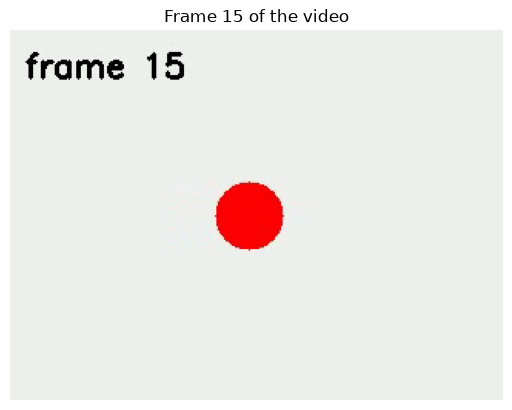

In [3]:
cap = cv2.VideoCapture("/tmp/synthetic.mp4")
print("Opened:", cap.isOpened())
print("Width:", cap.get(cv2.CAP_PROP_FRAME_WIDTH), "| Height:", cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
print("FPS:", cap.get(cv2.CAP_PROP_FPS), "| Frame count:", cap.get(cv2.CAP_PROP_FRAME_COUNT))
frames = []
while True:
    ok, frame = cap.read()
    if not ok:
        break
    frames.append(frame)
cap.release()
print("Frames actually read:", len(frames))
show(frames[15], "Frame 15 of the video")

## Processing frames in a loop

The universal video pattern: read a frame, process it, optionally write or display it, repeat. Here each frame is converted to grayscale edges and the processed frames are saved into a new video - a complete video-to-video pipeline.

In [4]:
cap = cv2.VideoCapture("/tmp/synthetic.mp4")
writer = cv2.VideoWriter("/tmp/edges.mp4", cv2.VideoWriter_fourcc(*"mp4v"), 10, (320, 240))
count = 0
while True:
    ok, frame = cap.read()
    if not ok:
        break
    edges = cv2.Canny(cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY), 50, 150)
    writer.write(cv2.cvtColor(edges, cv2.COLOR_GRAY2BGR))
    count += 1
cap.release(); writer.release()
print("Processed and wrote", count, "edge frames")

Processed and wrote 30 edge frames


## Extracting frames as images and seeking

Videos double as image datasets: save every Nth frame as an image for training or inspection. `cap.set(cv2.CAP_PROP_POS_FRAMES, n)` seeks directly to a frame index without reading everything before it.

In [5]:
cap = cv2.VideoCapture("/tmp/synthetic.mp4")
cap.set(cv2.CAP_PROP_POS_FRAMES, 20)
ok, frame20 = cap.read()
cap.release()
saved = []
cap = cv2.VideoCapture("/tmp/synthetic.mp4")
idx = 0
while True:
    ok, frame = cap.read()
    if not ok:
        break
    if idx % 10 == 0:
        path = f"/tmp/extracted_{idx:02d}.png"
        cv2.imwrite(path, frame)
        saved.append(path)
    idx += 1
cap.release()
print("Seek read ok:", ok, "| extracted files:", saved)

Seek read ok: False | extracted files: ['/tmp/extracted_00.png', '/tmp/extracted_10.png', '/tmp/extracted_20.png']


## The webcam pattern (run on your own machine)

For a live camera, `cv2.VideoCapture(0)` opens the default webcam - the rest of the loop is identical to file processing. Displaying needs a screen, so that part is shown as commented code. The processing function itself is tested here on a stored frame.

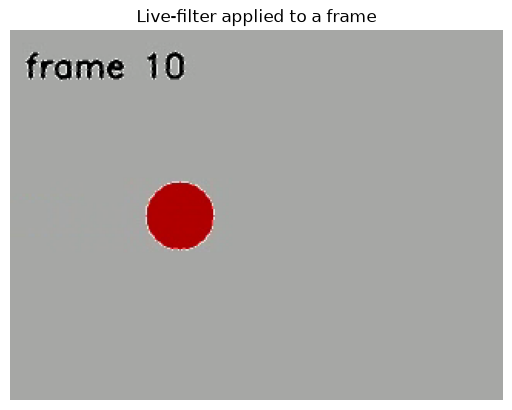

In [6]:
def process_live_frame(frame):
    """Example real-time filter: grayscale + edges blended with the original."""
    edges = cv2.Canny(cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY), 60, 160)
    return cv2.addWeighted(frame, 0.7, cv2.cvtColor(edges, cv2.COLOR_GRAY2BGR), 0.3, 0)

show(process_live_frame(frames[10]), "Live-filter applied to a frame")
# On your own machine:
# cap = cv2.VideoCapture(0)
# while True:
#     ok, frame = cap.read()
#     if not ok: break
#     cv2.imshow("webcam - press q to quit", process_live_frame(frame))
#     if cv2.waitKey(1) & 0xFF == ord("q"): break
# cap.release(); cv2.destroyAllWindows()

## Measuring real processing speed (FPS)

Real-time means processing faster than frames arrive. Timing a loop with `cv2.getTickCount` (or time.time) gives your true processing FPS - if it is below the video FPS, you must drop frames or optimise. Synthetic measurement on stored frames:

In [7]:
import time
start = time.time()
for f in frames:
    _ = cv2.Canny(cv2.cvtColor(f, cv2.COLOR_BGR2GRAY), 50, 150)
elapsed = time.time() - start
print(f"Processed {len(frames)} frames in {elapsed:.3f}s -> {len(frames) / elapsed:.1f} FPS")

Processed 30 frames in 0.007s -> 4034.1 FPS


## Key Points

- VideoCapture reads files and cameras with the same read() loop.
- VideoWriter needs FourCC, FPS and exact frame size; always release both objects.
- cap.get/set with CAP_PROP_* reads properties and seeks.
- Webcam = VideoCapture(0); display with imshow and quit on a key press with waitKey.
- Measure your processing FPS - real-time means processing at least as fast as the source.

## Mini Task

1. Create a 20-frame video of a rectangle moving downward and read it back, printing the frame count.
2. Extract and save frames 0, 5, 10 and 15 as PNG files.
3. Time how long Canny takes on all frames and report your machine's FPS.